# Homework II – Part II: Programming and critical analysis (`heart.csv`)
**Aprendizagem 2026/27 · Group Gxxx**

| Section | Content |
|---|---|
| 0 | Setup, data and shared helpers |
| 1 | 5-fold stratified CV: kNN (k=5) vs Gaussian Naïve Bayes, without and with Min-Max scaling |
| 2 | kNN: number of neighbours and weighting (70-30 split) |
| 3 | LIME explanations (3a evidence, 3b false negative, 3c stability) |
| 4 | Deployment decision (kNN vs Naïve Bayes) |

All random choices use `random_state=0` (or the explicit seeds stated in 3c). Optional parameters are left at their defaults.

## 0. Setup

In [1]:
# Bibliotecas padrão e de manipulação de dados
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validação cruzada, divisão treino/teste e modelos do sklearn
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
# Explicador LIME para dados tabulares
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")        # evita avisos que poluem o output
pd.set_option("display.precision", 4)    # 4 casas decimais nas tabelas

# Semente usada em todas as escolhas aleatórias (reprodutibilidade)
RANDOM_STATE = 0

In [2]:
# Carregar o dataset
df = pd.read_csv("heart.csv")

# Separar variáveis de entrada (features) e variável alvo (target)
X = df.drop(columns="outcome")
y = df["outcome"]
features = list(X.columns)   # nomes das variáveis, usados mais tarde no LIME

## 1. 5-fold stratified cross-validation
Stratified 5-fold with shuffling (`random_state=0`). Metrics: accuracy and recall of the positive class (`outcome = 1`, the default `pos_label`).

In [3]:
# Validação cruzada estratificada com 5 folds e baralhamento dos dados
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_summary(model):
    """Média e desvio padrão (entre folds) da accuracy e do recall da classe positiva."""
    # Calcula accuracy e recall (classe positiva = 1) em cada fold
    r = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "recall"])
    return {"acc mean": r["test_accuracy"].mean(), "acc std": r["test_accuracy"].std(),
            "recall mean": r["test_recall"].mean(), "recall std": r["test_recall"].std()}

### 1a) Raw data

In [4]:
# Comparação dos dois classificadores sobre os dados originais (sem pré-processamento)
table_1a = pd.DataFrame({
    "kNN (k=5)":   cv_summary(KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": cv_summary(GaussianNB()),
}).T   # transpor: uma linha por modelo
table_1a

,acc mean,acc std,recall mean,recall std
kNN (k=5),0.5915,0.0329,0.3286,0.0885
Naive Bayes,0.8167,0.0360,0.7662,0.0410


O **Naïve Bayes é o mais estável**. Na accuracy os desvios padrão são muito semelhantes (0.033 no kNN e 0.036 no NB; em valor relativo, 5.6% e 4.4% da média), mas no recall o desvio do NB é menos de metade do do kNN (0.041 contra 0.089, isto é, ≈5% contra ≈27% da média). O kNN sem escalamento deteta apenas cerca de um terço dos doentes e esse valor varia muito consoante os doentes que calham em cada fold de teste.

### 1b) With Min-Max scaling (inside a pipeline, so the scaler is fitted on each training fold only)

In [5]:
# Mesma avaliação, mas com Min-Max dentro de um pipeline:
# o scaler é ajustado apenas ao treino de cada fold, evitando fuga de informação (data leakage)
table_1b = pd.DataFrame({
    "MinMax + kNN (k=5)":   cv_summary(make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5))),
    "MinMax + Naive Bayes": cv_summary(make_pipeline(MinMaxScaler(), GaussianNB())),
}).T
table_1b

,acc mean,acc std,recall mean,recall std
MinMax + kNN (k=5),0.7920,0.0453,0.6295,0.0802
MinMax + Naive Bayes,0.8167,0.0360,0.7662,0.0410


In [6]:
# Vista lado a lado do efeito da normalização (sem scaling vs. com Min-Max)
pd.concat({"without scaling": table_1a, "with Min-Max": table_1b.rename(index=lambda s: s.replace("MinMax + ", ""))},
          names=["setting", "model"])

acc mean  acc std  recall mean  recall std
setting         model                                                  
without scaling kNN (k=5)      0.5915   0.0329       0.3286      0.0885
                Naive Bayes    0.8167   0.0360       0.7662      0.0410
with Min-Max    kNN (k=5)      0.7920   0.0453       0.6295      0.0802
                Naive Bayes    0.8167   0.0360       0.7662      0.0410

In [7]:
# Amplitude de cada variável (máximo - mínimo): relevante para a distância euclidiana do kNN
X.agg(["min", "max"]).T.assign(amplitude=lambda d: d["max"] - d["min"])

,min,max,amplitude
age,28.0,66.0,38.0
sex,0.0,1.0,1.0
chest_pain,1.0,4.0,3.0
trestbps,92.0,200.0,108.0
fasting_blood_sugar,0.0,1.0,1.0
restecg,0.0,2.0,2.0
thalach,82.0,190.0,108.0
exercise_induce_angina,0.0,1.0,1.0
oldpeak,0.0,5.0,5.0


- **Impacto no kNN: muito positivo** (+20 p.p. de accuracy e +30 p.p. de recall). O kNN usa a distância euclidiana, que soma as diferenças ao quadrado de todas as variáveis. Sem escalamento, as variáveis com maior amplitude (`trestbps` e `thalach`, com 108, e `age`, com 38) dominam a distância, enquanto variáveis clinicamente informativas mas de escala pequena (`sex`, `exercise_induce_angina` e `fasting_blood_sugar`, com amplitude 1; `restecg`, com 2; `chest_pain`, com 3) quase não influenciam a escolha dos vizinhos. Com o Min-Max todas ficam em $[0,1]$ e passam a contribuir numa escala comparável, pelo que os vizinhos passam a ser mais relevantes. O desvio padrão da accuracy subiu ligeiramente (0.033 → 0.045) e o do recall desceu (0.089 → 0.080).
- **Impacto no Naïve Bayes: nenhum** (resultados idênticos). O Min-Max é uma transformação afim por variável, $x' = (x-a)/b$. O GaussianNB ajusta uma gaussiana por variável e por classe, pelo que a média passa a $(\mu-a)/b$ e a variância a $\sigma^2/b^2$. A densidade de cada variável fica multiplicada pela mesma constante $1/b$ nas duas classes, e essa constante cancela-se na comparação das posteriores, logo a classe prevista não muda. (O `var_smoothing` por omissão também é proporcional à escala dos dados, pelo que não quebra esta equivalência.)
- Mesmo depois de escalar, o NB continua melhor (+2.5 p.p. de accuracy e +13.7 p.p. de recall), embora a diferença para o kNN tenha diminuído muito.
- O scaler está dentro do pipeline, logo é ajustado só com o treino de cada fold e não há fuga de informação (*data leakage*) para o fold de teste.

## 2. kNN: number of neighbours and weights
Stratified 70-30 split (`random_state=0`), Min-Max scaling inside the pipeline, $k \in \{1,5,10,15,20,25\}$, with `uniform` and `distance` weights.

In [8]:
# Divisão estratificada 70-30 (mantém a proporção das classes em treino e teste)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_tr)} patients | test: {len(X_te)} patients")

# Valores de k e tipos de ponderação a testar
ks = [1, 5, 10, 15, 20, 25]
weightings = ["uniform", "distance"]

# Para cada combinação (ponderação, k) treina o pipeline e guarda as accuracies de treino e de teste
rows = []
for weights in weightings:
    for k in ks:
        m = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k, weights=weights)).fit(X_tr, y_tr)
        rows.append({"weights": weights, "k": k,
                     "train acc": m.score(X_tr, y_tr), "test acc": m.score(X_te, y_te)})
results_k = pd.DataFrame(rows)
# Tabela resumo: k nas linhas, (ponderação, métrica) nas colunas
results_k.pivot(index="k", columns="weights", values=["train acc", "test acc"]).swaplevel(axis=1).sort_index(axis=1)

train: 198 patients | test: 86 patients


weights distance            uniform          
        test acc train acc test acc train acc
k                                            
1         0.7093       1.0   0.7093    1.0000
5         0.8256       1.0   0.8256    0.8333
10        0.8256       1.0   0.8605    0.8232
15        0.8140       1.0   0.8605    0.7980
20        0.8372       1.0   0.8721    0.7929
25        0.8721       1.0   0.8837    0.7828

### 2a) Train and test accuracy

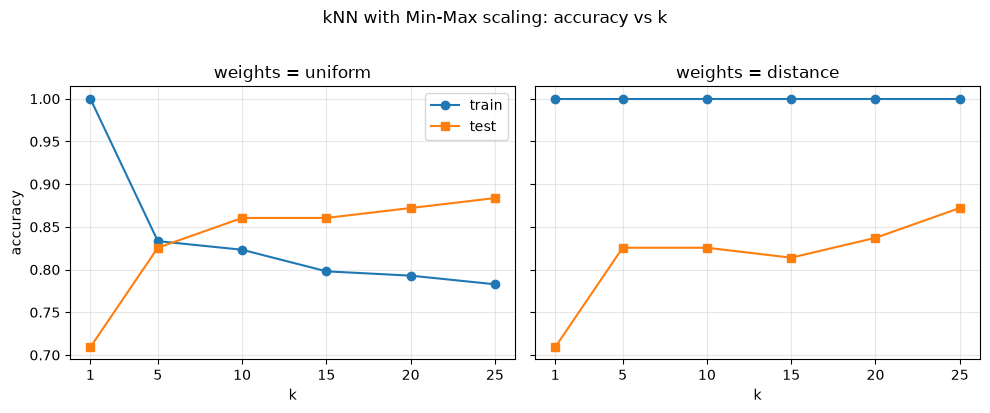

In [9]:
# Um gráfico por tipo de ponderação, com o mesmo eixo y para facilitar a comparação
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, weights in zip(axes, weightings):
    sub = results_k[results_k["weights"] == weights]
    ax.plot(sub["k"], sub["train acc"], "o-", label="train")   # accuracy de treino
    ax.plot(sub["k"], sub["test acc"], "s-", label="test")     # accuracy de teste
    ax.set(title=f"weights = {weights}", xlabel="k", xticks=ks)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy")
axes[0].legend()
fig.suptitle("kNN with Min-Max scaling: accuracy vs k", y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# Verificação adicional: o mesmo estudo com validação cruzada (5 folds) sobre todos os dados, para ver se a
# tendência da divisão única (apenas 86 doentes de teste) se mantém. Não substitui a divisão pedida no enunciado.
cv_k = {w: [cross_validate(make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k, weights=w)),
                           X, y, cv=cv)["test_score"].mean() for k in ks] for w in weightings}
print("Accuracy da classe maioritária (referência): %.3f" % max(y.mean(), 1 - y.mean()))
pd.DataFrame(cv_k, index=pd.Index(ks, name="k")).round(3)

Accuracy da classe maioritária (referência): 0.637


,uniform,distance
k,,
1,0.760,0.760
5,0.792,0.799
10,0.820,0.806
15,0.820,0.820
20,0.810,0.817
25,0.803,0.799


**Resposta 2b)**

**Efeito de aumentar $k$ na generalização**
- **$k=1$:** accuracy de treino de 100% (cada doente é o seu próprio vizinho a distância 0), mas só 70.9% no teste. A diferença de ≈29 p.p. é overfitting: a fronteira de decisão segue cada ponto de treino, incluindo o ruído.
- **$k$ a crescer (pesos uniformes):** a accuracy de treino desce (0.833, 0.823, 0.798, 0.793 e 0.783 para $k=5,10,15,20,25$) e a de teste sobe (0.826, 0.860, 0.860, 0.872 e 0.884). Cada previsão passa a depender de mais vizinhos, a fronteira fica mais suave e menos sensível a doentes individuais ou ruído (menor variância), à custa de um viés maior, que é o que faz descer a accuracy de treino.
- **$k$ demasiado grande:** haveria *underfitting* (no limite $k=n$ prevê-se sempre a classe maioritária, ≈64%) porque os vizinhos deixam de ser parecidos com o doente. Isso ainda não se vê na grelha testada: com $k=25$ a accuracy de treino (0.78) continua bem acima da classe maioritária.

**Trade-off:** $k$ pequeno dá viés baixo e variância alta (um único vizinho ruidoso decide); $k$ grande dá variância baixa e viés alto (fronteira demasiado simples).

**Pesos por distância:** a accuracy de treino é 100% para todos os $k$, porque o próprio ponto está a distância 0 e domina o voto, pelo que deixa de ser informativa sobre o overfitting. No teste, a accuracy é igual ou inferior à dos pesos uniformes em todos os $k$ (por exemplo, 0.814 contra 0.860 com $k=15$): os vizinhos mais próximos dominam o voto, o que equivale a um $k$ efetivo menor e a menos suavização.

**Teste acima do treino:** para $k \ge 10$ a accuracy de teste (0.86–0.88) supera a de treino (0.78–0.82), o que sugere que esta divisão em particular é favorável (86 doentes de teste: um doente vale ≈1.2 p.p. e o erro padrão de uma accuracy de 0.85 é ≈3.8 p.p.). A validação cruzada acima dá apenas 0.80–0.82 para $k \in [10, 25]$ e deixa de melhorar a partir de $k=15$, ao contrário da subida contínua até $k=25$ que se vê na divisão única.

**$k$ ótimo:** propõe-se o **intervalo $k \in [10, 20]$ com pesos uniformes** (se for preciso um único valor, $k=15$, o centro do intervalo). Não se escolhe um único valor porque as diferenças entre $k=10$ e $k=25$ equivalem a 1–2 doentes no teste e a ≈1 p.p. na validação cruzada, dentro do ruído; além disso, $k=25$ é o limite da grelha, pelo que não se sabe o que acontece acima. Já $k=1$ e $k=5$ são claramente piores.

## 3. LIME explanations
Both pipelines (Min-Max → kNN with k=5, Min-Max → Naïve Bayes) are trained on the split of Section 2. LIME works on the **unscaled** training data and receives the `predict_proba` of the **full pipeline**, so explanations refer to the original units.

In [11]:
# Usar arrays (e não DataFrames) para que os pipelines e o LIME recebam exatamente o mesmo tipo de input
X_train, X_test = X_tr.to_numpy(), X_te.to_numpy()
y_train, y_test = y_tr.to_numpy(), y_te.to_numpy()

# Treinar os dois pipelines (Min-Max + kNN com k=5 e Min-Max + Naïve Bayes) com a divisão da secção 2
knn = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
nb  = make_pipeline(MinMaxScaler(), GaussianNB()).fit(X_train, y_train)
models = {"kNN": knn, "NB": nb}

# Previsões de cada modelo no conjunto de teste
pred_knn, pred_nb = knn.predict(X_test), nb.predict(X_test)

def explain(model, x, seed=0, num_samples=5000):
    # Cria um explicador novo por cada explicação (como pedido no enunciado),
    # para que os resultados não dependam da ordem das chamadas
    # O explicador usa o treino SEM normalização, pelo que as explicações ficam nas unidades originais
    explainer = LimeTabularExplainer(
        X_train, feature_names=features, class_names=["no disease", "disease"],
        mode="classification", random_state=seed)
    # predict_proba do pipeline completo (inclui o scaler); 5 variáveis na explicação
    return explainer.explain_instance(x, model.predict_proba, num_features=5, num_samples=num_samples)

def show_explanations(idx, title, plot=True):
    """Imprime (e, se plot=True, desenha) a explicação LIME do doente de teste `idx` para ambos os modelos."""
    # Valores do doente (uma variável por linha, para ler sem fazer scroll) e classe verdadeira
    print("Patient (test position %d) | true label: %d" % (idx, y_test[idx]))
    display(X_te.iloc[idx].map("{:g}".format).to_frame("value"))
    for name, model in models.items():
        # Probabilidade de doença, previsão do modelo e explicação LIME
        p = model.predict_proba(X_test[idx:idx + 1])[0, 1]
        exp = explain(model, X_test[idx])
        print(f"\n{name}: P(disease) = {p:.3f} | prediction = {model.predict(X_test[idx:idx+1])[0]} | fidelity R² = {exp.score:.3f}")
        # Condições e pesos: positivo empurra para "doença", negativo para "sem doença"
        for cond, w in exp.as_list():
            print(f"   {w:+.3f}  {cond}")
        # Gráfico de barras com os pesos (opcional)
        if plot:
            exp.as_pyplot_figure()
            plt.title(f"{name} – {title}")
            plt.tight_layout()
            plt.show()

### 3a) First test patient with disease that both models classify correctly

Patient (test position 1) | true label: 1


,value
age,52
sex,1
chest_pain,4
trestbps,112
fasting_blood_sugar,0
restecg,1
thalach,96
exercise_induce_angina,1
oldpeak,1



kNN: P(disease) = 0.600 | prediction = 1 | fidelity R² = 0.537
   +0.290  0.00 < exercise_induce_angina <= 1.00
   +0.265  3.00 < chest_pain <= 4.00
   -0.255  fasting_blood_sugar <= 0.00
   +0.212  0.00 < sex <= 1.00
   +0.032  thalach <= 120.00


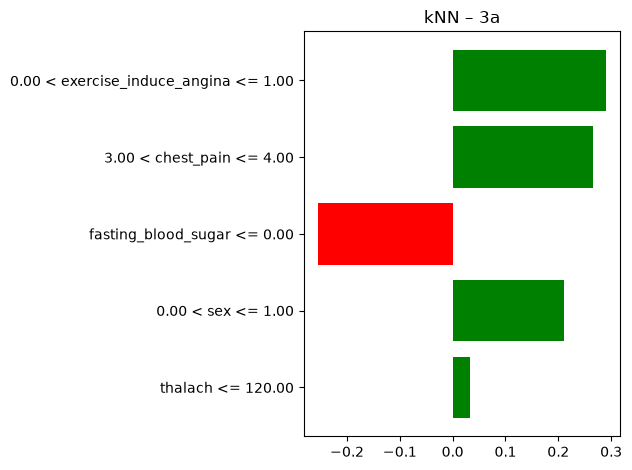


NB: P(disease) = 0.983 | prediction = 1 | fidelity R² = 0.454
   -0.676  fasting_blood_sugar <= 0.00
   +0.374  0.00 < exercise_induce_angina <= 1.00
   +0.266  0.00 < sex <= 1.00
   +0.168  3.00 < chest_pain <= 4.00
   -0.128  restecg > 0.00


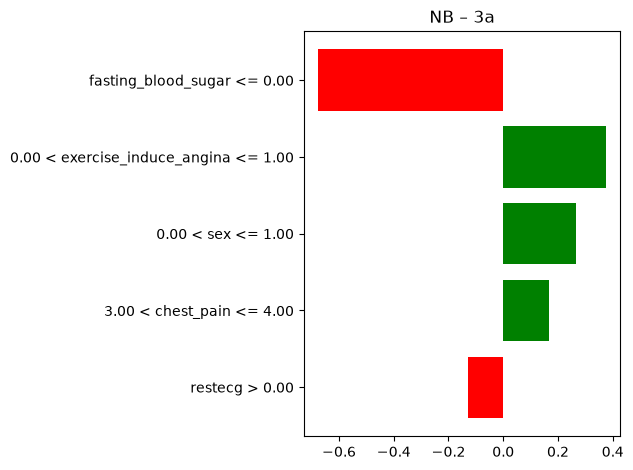

In [12]:
# Primeiro doente de teste com doença que ambos os modelos classificam corretamente
idx_a = next(j for j in range(len(X_test)) if y_test[j] == 1 and pred_knn[j] == 1 and pred_nb[j] == 1)
show_explanations(idx_a, "3a")

In [13]:
# Verificação: explicações com as 9 variáveis (e não só o top-5) para ver onde ficam thalach e restecg,
# e previsão do modelo linear do LIME (local_pred) comparada com a probabilidade real do modelo
for name, model in models.items():
    full = LimeTabularExplainer(X_train, feature_names=features, class_names=["no disease", "disease"],
                                mode="classification", random_state=0
                               ).explain_instance(X_test[idx_a], model.predict_proba, num_features=9, num_samples=5000)
    print(name, "| 9 variáveis:", [(c, round(w, 3)) for c, w in full.as_list()])
    top5 = explain(model, X_test[idx_a])
    print(f"   P(disease) do modelo = {model.predict_proba(X_test[idx_a:idx_a+1])[0, 1]:.3f} | previsão local do LIME = {top5.local_pred[0]:.3f}\n")

kNN | 9 variáveis: [('0.00 < exercise_induce_angina <= 1.00', 0.29), ('3.00 < chest_pain <= 4.00', 0.265), ('fasting_blood_sugar <= 0.00', -0.255), ('0.00 < sex <= 1.00', 0.212), ('thalach <= 120.00', 0.032), ('restecg > 0.00', -0.014), ('trestbps <= 120.00', 0.013), ('49.00 < age <= 54.00', 0.009), ('0.00 < oldpeak <= 1.00', 0.0)]
   P(disease) do modelo = 0.600 | previsão local do LIME = 0.755

NB | 9 variáveis: [('fasting_blood_sugar <= 0.00', -0.678), ('0.00 < exercise_induce_angina <= 1.00', 0.375), ('0.00 < sex <= 1.00', 0.264), ('3.00 < chest_pain <= 4.00', 0.168), ('restecg > 0.00', -0.129), ('thalach <= 120.00', 0.108), ('trestbps <= 120.00', -0.05), ('49.00 < age <= 54.00', 0.024), ('0.00 < oldpeak <= 1.00', -0.007)]
   P(disease) do modelo = 0.983 | previsão local do LIME = 0.667



**Resposta 3a) – os dois modelos usam a mesma evidência?** Em grande parte, sim. Ambos preveem doença para este doente (kNN: P = 0.60; NB: P = 0.98) e apoiam-se nas mesmas quatro condições, com os mesmos sinais:
- empurram para **doença**: `exercise_induce_angina = 1` (+0.29 no kNN, +0.37 no NB), `chest_pain = 4` (+0.27 e +0.17) e `sex = 1` (+0.21 e +0.27);
- empurra para **saudável**: `fasting_blood_sugar = 0` (−0.26 e −0.68).

Só a 5.ª condição difere (`thalach ≤ 120` no kNN, `restecg > 0` no NB), mas com as 9 variáveis vê-se que são apenas o 5.º e o 6.º lugares trocados, ambos com pesos pequenos (kNN: `thalach` +0.032 e `restecg` −0.014; NB: `restecg` −0.129 e `thalach` +0.108). O corte em 5 variáveis é que esconde a que fica em 6.º. Os modelos diferem mais na magnitude dos pesos e na confiança (0.60 contra 0.98) do que na evidência. Convém ainda notar que a fidelidade é moderada (R² = 0.54 no kNN e 0.45 no NB) e que a previsão local do LIME não reproduz as probabilidades dos modelos (0.75 contra 0.60 no kNN; 0.67 contra 0.98 no NB), pelo que as explicações devem ler-se de forma qualitativa.

**Why does Naïve Bayes weight `fasting_blood_sugar` so much?** Parameters of the Gaussian estimated by NB for this variable (last pipeline step; values are on the Min-Max scale, which does not change a 0/1 variable):

In [14]:
# Último passo do pipeline do NB (o GaussianNB) e índice da variável fasting_blood_sugar
gnb = nb[-1]
j = features.index("fasting_blood_sugar")

# Parâmetros da gaussiana desta variável em cada classe (média, variância) e priors
params = pd.DataFrame({"mean (theta_)": gnb.theta_[:, j], "variance (var_)": gnb.var_[:, j],
                       "prior": gnb.class_prior_}, index=["no disease (0)", "disease (1)"])
display(params)
# Contagens reais de fasting_blood_sugar por classe no treino
# Contagens reais no treino, com rótulos legíveis (linhas = valor da variável, colunas = classe)
contagens = pd.crosstab(X_tr["fasting_blood_sugar"], y_tr, margins=True, margins_name="total")
contagens.columns = ["no disease (0)", "disease (1)", "total"]
contagens.index = ["fasting_blood_sugar = 0", "fasting_blood_sugar = 1", "total"]
display(contagens)

def gauss_pdf(v, mu, var):
    # Densidade da distribuição normal N(mu, var) no ponto v
    return np.exp(-(v - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

# Verosimilhança de fasting_blood_sugar = 0 e = 1 em cada classe
p0 = gauss_pdf(np.array([0.0, 1.0]), gnb.theta_[0, j], gnb.var_[0, j])
p1 = gauss_pdf(np.array([0.0, 1.0]), gnb.theta_[1, j], gnb.var_[1, j])
# Razão de verosimilhanças: quanto cada valor favorece "doença" face a "sem doença"
pd.DataFrame({"p(v | no disease)": p0, "p(v | disease)": p1, "likelihood ratio disease/no disease": p1 / p0},
             index=["fasting_blood_sugar = 0", "fasting_blood_sugar = 1"])

,mean (theta_),variance (var_),prior
no disease (0),0.0238,0.0232,0.6364
disease (1),0.1389,0.1196,0.3636


,no disease (0),disease (1),total
fasting_blood_sugar = 0,123,62,185
fasting_blood_sugar = 1,3,10,13
total,126,72,198


,p(v | no disease),p(v | disease),likelihood ratio disease/no disease
fasting_blood_sugar = 0,2.5851e+00,1.0642,4.1167e-01
fasting_blood_sugar = 1,3.2714e-09,0.0520,1.5886e+07


**Resposta 3a) – porque é que o Naïve Bayes dá tanto peso a `fasting_blood_sugar`?**
- A variável é binária (no treino, só 13 de 198 doentes têm valor 1: 3 saudáveis e 10 doentes), mas o GaussianNB modela-a com uma gaussiana por classe. Como quase todos os saudáveis têm 0, a gaussiana dos saudáveis é muito estreita ($\mu=0.024$, $\sigma^2=0.023$, $\sigma\approx0.152$), enquanto a dos doentes é bastante mais larga ($\mu=0.139$, $\sigma^2=0.120$, $\sigma\approx0.346$).
- O valor 1 fica a $(1-0.024)/0.152 \approx 6.4$ desvios padrão da média dos saudáveis, mas só a $(1-0.139)/0.346 \approx 2.5$ da dos doentes. Assim, $p(1\mid\text{saudável}) \approx 3.3\times10^{-9}$ e $p(1\mid\text{doente}) \approx 0.052$, uma razão de $\approx 1.6\times10^{7}$ a favor de doença (para o valor 0 a razão é só 0.41). Nos dados a razão real é $(10/72)/(3/126) \approx 5.8$, pelo que a gaussiana exagera enormemente a cauda de uma variável binária.
- O LIME gera amostras artificiais em torno do doente, algumas com `fasting_blood_sugar = 1`. No NB, essas amostras ficam com P(doença) ≈ 1 quase independentemente das restantes variáveis, porque um fator de $10^7$ supera as razões das outras variáveis (tipicamente de ordem de grandeza 1). O modelo linear vê então a condição `fasting_blood_sugar ≤ 0` separar quase perfeitamente os dois comportamentos e atribui-lhe um peso grande (−0.68).
- No kNN a variável é apenas uma das 9 coordenadas da distância. Passar para 1 aproxima a amostra dos 13 doentes com esse valor, mas a previsão continua a ser um voto de 5 vizinhos que depende também das outras variáveis, pelo que o efeito é menor e menos sistemático (−0.26).
- O peso do LIME mede a sensibilidade do modelo à variável nas perturbações, não a contribuição do valor observado (0) neste doente: no NB esse valor só multiplica as odds por 0.41.

### 3b) First test patient that is a false negative for at least one model

In [15]:
# Primeiro doente de teste com doença que é falso negativo em pelo menos um dos modelos
idx_b = next(j for j in range(len(X_test)) if y_test[j] == 1 and (pred_knn[j] == 0 or pred_nb[j] == 0))
print("Predictions -> kNN:", pred_knn[idx_b], "| NB:", pred_nb[idx_b], "\n")
show_explanations(idx_b, "3b", plot=False)   # o enunciado não pede gráficos na 3b

Predictions -> kNN: 0 | NB: 0 

Patient (test position 3) | true label: 1


,value
age,39
sex,1
chest_pain,4
trestbps,110
fasting_blood_sugar,0
restecg,0
thalach,150
exercise_induce_angina,0
oldpeak,0



kNN: P(disease) = 0.400 | prediction = 0 | fidelity R² = 0.572
   -0.288  exercise_induce_angina <= 0.00
   +0.271  3.00 < chest_pain <= 4.00
   -0.249  fasting_blood_sugar <= 0.00
   +0.207  0.00 < sex <= 1.00
   -0.123  oldpeak <= 0.00

NB: P(disease) = 0.049 | prediction = 0 | fidelity R² = 0.634
   -0.684  fasting_blood_sugar <= 0.00
   -0.389  oldpeak <= 0.00
   -0.370  exercise_induce_angina <= 0.00
   +0.252  0.00 < sex <= 1.00
   +0.156  3.00 < chest_pain <= 4.00


In [16]:
# Referência: como se compara este doente com o doente típico de cada classe (médias no treino)?
ref = pd.DataFrame({"patient": X_te.iloc[idx_b],
                    "mean healthy (train)": X_tr[y_tr == 0].mean(),
                    "mean disease (train)": X_tr[y_tr == 1].mean()})
ref

,patient,mean healthy (train),mean disease (train)
age,39.0,46.7143,50.3750
sex,1.0,0.6349,0.9167
chest_pain,4.0,2.5873,3.5417
trestbps,110.0,131.1270,136.9444
fasting_blood_sugar,0.0,0.0238,0.1389
restecg,0.0,0.2460,0.1389
thalach,150.0,145.0397,129.0000
exercise_induce_angina,0.0,0.1111,0.6111
oldpeak,0.0,0.2048,1.2153


In [17]:
# Verificações adicionais ao falso negativo da 3b
x_fn = X_test[idx_b:idx_b + 1]

# (1) Probabilidade do modelo vs. previsão do modelo linear do LIME no próprio doente
for name, model in models.items():
    exp = explain(model, X_test[idx_b])
    print(f"{name}: P(disease) = {model.predict_proba(x_fn)[0, 1]:.3f} | previsão local do LIME = {exp.local_pred[0]:.3f} | R² = {exp.score:.3f}")

# (2) Classes dos 5 vizinhos do kNN (no espaço normalizado)
_, nn = knn[-1].kneighbors(knn[0].transform(x_fn))
print("\nClasses dos 5 vizinhos do kNN:", y_train[nn[0]])

# (3) NB: razão de verosimilhanças doença/saudável de cada variável no valor deste doente (>1 favorece doença)
g = nb[-1]
xs = nb[0].transform(x_fn)[0]
def log_dens(v, c):
    return -0.5 * np.log(2 * np.pi * g.var_[c]) - (v - g.theta_[c]) ** 2 / (2 * g.var_[c])
print("\nNB – razão de verosimilhanças por variável (prior doença/saudável = %.2f):" % (g.class_prior_[1] / g.class_prior_[0]))
print(pd.Series(np.exp(log_dens(xs, 1) - log_dens(xs, 0)), index=features).round(2).to_string())

# (4) Treino: doentes com o mesmo perfil e taxa de doença por tipo de dor
perfil = ((X_tr["sex"] == 1) & (X_tr["chest_pain"] == 4) & (X_tr["exercise_induce_angina"] == 0)
          & (X_tr["oldpeak"] == 0) & (X_tr["fasting_blood_sugar"] == 0))
print("\nTreino – mesmo perfil (homem, chest_pain=4, sem angina, oldpeak=0, glicemia normal):", y_tr[perfil].value_counts().to_dict())
print("Treino – taxa de doença com chest_pain=4: %.2f | com outros tipos de dor: %.2f"
      % (y_tr[X_tr["chest_pain"] == 4].mean(), y_tr[X_tr["chest_pain"] != 4].mean()))

kNN: P(disease) = 0.400 | previsão local do LIME = 0.401 | R² = 0.572
NB: P(disease) = 0.049 | previsão local do LIME = 0.249 | R² = 0.634

Classes dos 5 vizinhos do kNN: [0 1 0 1 0]

NB – razão de verosimilhanças por variável (prior doença/saudável = 0.57):
age                       0.53
sex                       2.22
chest_pain                3.32
trestbps                  0.69
fasting_blood_sugar       0.41
restecg                   1.50
thalach                   0.65
exercise_induce_angina    0.31
oldpeak                   0.26

Treino – mesmo perfil (homem, chest_pain=4, sem angina, oldpeak=0, glicemia normal): {0: 12, 1: 12}
Treino – taxa de doença com chest_pain=4: 0.66 | com outros tipos de dor: 0.17


**Resposta 3b)** O primeiro falso negativo é o doente 3 do teste (homem de 39 anos com `chest_pain = 4`, sem angina de esforço, `oldpeak = 0` e glicemia normal), classificado como saudável pelos **dois** modelos (kNN: P(doença) = 0.40; NB: 0.05).

**Condições que empurraram para a classe errada:** três condições de *ausência* de sinais, todas com peso negativo: `exercise_induce_angina = 0` (kNN −0.29, NB −0.37), `fasting_blood_sugar = 0` (−0.25 e −0.68) e `oldpeak = 0` (−0.12 e −0.39). `chest_pain = 4` (+0.27 e +0.16) e `sex = 1` (+0.21 e +0.25) empurram para doença, mas não chegam para as compensar.

**Fidelidade:** R² = 0.57 (kNN) e R² = 0.63 (NB). O modelo linear explica só cerca de 60% da variação local do modelo.

**A explicação é de confiança?** Só parcialmente. As duas explicações coincidem nas condições principais, o que lhes dá alguma credibilidade, mas há sinais de cautela:
- Com R² ≈ 0.6, ≈40% do comportamento local fica por explicar. No kNN a previsão local do LIME no doente coincide com a do modelo (0.40), mas no NB é 0.25 contra 0.05 do modelo, pelo que os pesos não "somam" a previsão real.
- No NB o LIME põe `fasting_blood_sugar = 0` em 1.º lugar (−0.68), mas na conta do próprio modelo esse valor só multiplica as odds por 0.41, menos do que `oldpeak = 0` (0.26) ou a ausência de angina (0.31). O peso reflete, como visto na 3a, a reação extrema do modelo a `fasting_blood_sugar = 1` nas perturbações e não a razão real da previsão.
- No kNN a probabilidade só toma valores em passos de 0.2 (voto de 5 vizinhos), difícil de aproximar por um modelo linear. Aqui, 3 vizinhos são saudáveis e 2 doentes, logo a previsão é decidida por um único voto.
- Em qualquer caso, o LIME descreve o que o modelo faz, não se o modelo está certo.

**Como um clínico podia suspeitar do erro:**
- O kNN estava no limite (0.40 contra 0.60), pelo que a previsão não era confiante.
- Tanto `chest_pain = 4` (dor assintomática) como `sex = 1` são fatores de risco (no treino, 66% dos doentes com `chest_pain = 4` têm doença, contra 17% nos restantes), e a explicação mostra que só foram compensados por achados normais. Esses achados não excluem doença: no treino, os doentes com este mesmo perfil dividem-se 12 contra 12, pelo que uma probabilidade de 0.05 (NB) não tem base nos dados.
- A "razão principal" do NB, glicemia normal, é uma evidência clínica fraca: 62 dos 72 doentes do treino também a têm normal.

### 3c) Explanation stability (kNN, patient of 3a)
10 explanations per setting, seeds 0–9, with `num_samples = 500` and `5000`. For every variable we record in how many runs it enters the top-5, its mean rank in the top-5 (1 = largest |weight|), how often it is ranked first, and the standard deviation of its weight (only meaningful when it appears in at least 2 runs).

In [18]:
SEEDS = range(10)   # sementes 0 a 9 do explicador
rows, fidelity = [], {}

for ns in [500, 5000]:
    # Para cada variável guarda (posição, peso) em cada execução em que entra no top-5
    appearances = {f: [] for f in features}
    r2 = []   # fidelidade (R²) de cada explicação
    for s in SEEDS:
        # Nova explicação do doente de 3a para o kNN, com esta semente e este nº de amostras
        exp = explain(knn, X_test[idx_a], seed=s, num_samples=ns)
        r2.append(exp.score)
        # as_map() devolve as variáveis ordenadas por |peso|, logo a posição = ranking no top-5
        for rank, (f_idx, w) in enumerate(exp.as_map()[1], start=1):
            appearances[features[f_idx]].append((rank, w))
    fidelity[ns] = (np.mean(r2), np.std(r2))
    # Estatísticas por variável: nº de vezes no top-5, ranking médio, nº de vezes em 1.º, média e desvio padrão do peso
    for f, app in appearances.items():
        ranks = [a[0] for a in app]
        weights = [a[1] for a in app]
        rows.append({"num_samples": ns, "variable": f, "top5 count": len(app),
                     "mean rank": np.mean(ranks) if app else np.nan,
                     "times rank 1": sum(r == 1 for r in ranks),
                     "mean weight": np.mean(weights) if app else np.nan,
                     # desvio padrão só faz sentido com pelo menos 2 observações
                     "std weight": np.std(weights) if len(app) >= 2 else np.nan})

stability = pd.DataFrame(rows).set_index(["num_samples", "variable"])
# Fidelidade média ± desvio padrão para cada num_samples
for ns, (m_, s_) in fidelity.items():
    print(f"num_samples={ns}: fidelity R² = {m_:.3f} ± {s_:.3f}")
stability

num_samples=500: fidelity R² = 0.524 ± 0.035
num_samples=5000: fidelity R² = 0.530 ± 0.012


top5 count  mean rank  times rank 1  \
num_samples variable                                                      
500         age                              1        5.0             0   
            sex                             10        3.5             0   
            chest_pain                      10        1.7             4   
            trestbps                         1        5.0             0   
            fasting_blood_sugar             10        3.4             0   
            restecg                          3        5.0             0   
            thalach                          3        5.0             0   
            exercise_induce_angina          10        1.4             6   
            oldpeak                          2        5.0             0   
5000        age                              3        5.0             0   
            sex                             10        4.0             0   
            chest_pain                      10        2.2             0   
            trestbps                         0        NaN             0   
            fasting_blood_sugar             10        2.8             0   
            restecg                          1        5.0             0   
            thalach                          5        5.0             0   
            exercise_induce_angina          10        1.0            10   
            oldpeak                          1        5.0             0   

                                    mean weight  std weight  
num_samples variable                                         
500         age                          0.0326         NaN  
            sex                          0.2068      0.0173  
            chest_pain                   0.2719      0.0201  
            trestbps                     0.0387         NaN  
            fasting_blood_sugar         -0.2050      0.0379  
            restecg                     -0.0293      0.0027  
            thalach                      0.0339      0.0142  
            exercise_induce_angina       0.2783      0.0248  
            oldpeak                     -0.0294      0.0081  
5000        age                          0.0169      0.0060  
            sex                          0.2157      0.0046  
            chest_pain                   0.2562      0.0057  
            trestbps                        NaN         NaN  
            fasting_blood_sugar         -0.2411      0.0122  
            restecg                     -0.0129         NaN  
            thalach                      0.0243      0.0066  
            exercise_induce_angina       0.2950      0.0078  
            oldpeak                     -0.0144         NaN

In [19]:
# Quantas ordens diferentes do top-5 aparecem nas 10 explicações, e que variáveis ocupam a 5.ª posição
for ns in [500, 5000]:
    ordens = []
    for s in SEEDS:
        exp = explain(knn, X_test[idx_a], seed=s, num_samples=ns)
        ordens.append(tuple(features[j] for j, _ in exp.as_map()[1]))
    print(f"num_samples={ns}: {len(set(ordens))} ordens distintas do top-5 | 5.ª posição: {dict(Counter(o[-1] for o in ordens))}")

num_samples=500: 9 ordens distintas do top-5 | 5.ª posição: {'oldpeak': 2, 'trestbps': 1, 'restecg': 3, 'thalach': 3, 'age': 1}
num_samples=5000: 5 ordens distintas do top-5 | 5.ª posição: {'thalach': 5, 'age': 3, 'restecg': 1, 'oldpeak': 1}


**Resposta 3c)** (kNN, doente da 3a, sementes 0 a 9)

| | `num_samples = 500` | `num_samples = 5000` |
|---|---|---|
| Presentes em 10/10 explicações | `exercise_induce_angina` (peso médio +0.278, desvio padrão 0.025), `chest_pain` (+0.272; 0.020), `sex` (+0.207; 0.017), `fasting_blood_sugar` (−0.205; 0.038) | as mesmas quatro: +0.295 (0.008), +0.256 (0.006), +0.216 (0.005) e −0.241 (0.012) |
| 5.ª posição | `thalach` (3/10), `restecg` (3/10), `oldpeak` (2/10), `trestbps` (1/10), `age` (1/10) | `thalach` (5/10), `age` (3/10), `restecg` (1/10), `oldpeak` (1/10) |
| Ordens distintas do top-5 | 9 em 10 | 5 em 10 |
| Fidelidade R² (média ± desvio padrão) | 0.524 ± 0.035 | 0.530 ± 0.012 |

(O desvio padrão dos pesos das variáveis que só aparecem uma vez não está definido.)

**O que se pode confiar numa explicação única:**
- **As variáveis do top-5 com peso grande:** as quatro principais aparecem sempre, mesmo com 500 amostras. Já a 5.ª é pouco fiável: os candidatos têm pesos pequenos (≈0.01–0.03), comparáveis à variação entre sementes, pelo que a variável que aparece depende da semente.
- **Os pesos:** o sinal e a ordem de grandeza dos pesos das quatro principais são fiáveis. O desvio padrão desce 3 a 4 vezes ao passar de 500 para 5000 amostras (≈$\sqrt{10}$, como esperado), pelo que os valores são mais fiáveis com $N$ elevado.
- **A ordem:** só é fiável quando os pesos estão claramente afastados. Com 5000 amostras, `exercise_induce_angina` fica sempre em 1.º, mas `chest_pain` e `fasting_blood_sugar` (|pesos| 0.256 e 0.241) trocam entre 2.º e 3.º lugar, e com 500 amostras quase todas as ordens são diferentes.

**Em que situações não se pode confiar:** com poucas amostras (500); quando os pesos são pequenos ou muito próximos (quinta posição, ordem entre variáveis semelhantes); e quando a fidelidade é baixa. Aqui o R² é de ≈0.53 em ambos os casos: aumentar o número de amostras torna a explicação **mais estável**, mas **não mais fiel** ao modelo, porque o limite está no modelo linear usado como aproximação. Uma explicação estável pode, portanto, estar sistematicamente errada (como o peso de `fasting_blood_sugar` no NB na 3b).

In [20]:
# Desempenho no conjunto de teste da secção 2 (matriz de confusão: [[TN, FP], [FN, TP]])
from sklearn.metrics import recall_score, confusion_matrix
for name, model in models.items():
    pred = model.predict(X_test)
    print(f"{name}: accuracy = {model.score(X_test, y_test):.3f} | recall = {recall_score(y_test, pred):.3f} | confusão = {confusion_matrix(y_test, pred).tolist()}")

kNN: accuracy = 0.826 | recall = 0.710 | confusão = [[49, 6], [9, 22]]
NB: accuracy = 0.849 | recall = 0.871 | confusão = [[46, 9], [4, 27]]


## 4. Deployment decision

**Escolha: Naïve Bayes (Gaussiano).**

**Razão 1 – maior recall, e mais estável.** Num diagnóstico, um falso negativo (doente que fica sem tratamento) é mais grave do que um falso positivo (exames adicionais). Na validação cruzada (1b) o NB tem recall de 0.766 ± 0.041 contra 0.630 ± 0.080 do kNN (com Min-Max), ou seja, deteta mais doentes com metade da variabilidade, e também tem melhor accuracy (0.817 contra 0.792). Na divisão do exercício 2 isso repete-se: no teste, o NB deteta 27 de 31 doentes (recall 0.87) e o kNN com $k=5$ só 22 (0.71). Mesmo assim, um recall de ≈77% significa que ≈1 em cada 4 doentes escapa, pelo que o modelo deve apoiar o clínico e não substituí-lo.

**Razão 2 – não depende do pré-processamento nem de hiperparâmetros.** O NB dá resultados idênticos com e sem Min-Max (1a contra 1b), enquanto o kNN passa de 0.592 para 0.792 de accuracy e de 0.329 para 0.630 de recall consoante a escala das variáveis: um erro de escala em produção degradaria o kNN sem aviso. O kNN depende ainda de $k$ e dos pesos (no exercício 2, a accuracy de teste variou entre 0.71 e 0.88), enquanto o NB não tem hiperparâmetros relevantes.

**O kNN com $k$ grande chega a 0.88 de accuracy no teste (exercício 2): isso contraria a escolha?** Não de forma conclusiva: é uma única divisão com 86 doentes e mede accuracy e não recall, que é o que mais pesa num diagnóstico, e a validação cruzada (≈0.80–0.82) não confirma esse valor.

**As explicações LIME seriam suficientes para justificar o deploy do kNN? Não.** Os resultados do exercício 3 mostram porquê:
- **Fidelidade moderada (3b):** no falso negativo, o R² da explicação do kNN é 0.57 (≈43% do comportamento local por explicar). O kNN falhou este doente (P(doença) = 0.40) e a explicação, plausível do ponto de vista clínico, não o revelou: o LIME descreve o que o modelo faz, não se acerta.
- **Instabilidade (3c):** só quatro variáveis são estáveis; a 5.ª muda com a semente (com $N=5000$, `thalach` aparece em 5/10 explicações e `age` em 3/10) e o R² não melhora com mais amostras (0.52 contra 0.53), pelo que estabilidade não é fidelidade.
- **Âmbito local:** o LIME explica uma previsão de cada vez e não mede o desempenho global (recall, sensibilidade ao pré-processamento), que é o que justifica um deploy. Serve como auditoria complementar, mas a decisão tem de assentar em métricas globais validadas, que favorecem o Naïve Bayes.

**Ressalva sobre o NB:** é interpretável diretamente (`theta_` e `var_` explicaram o peso de `fasting_blood_sugar` na 3a), mas as gaussianas exageram o efeito de valores raros de variáveis binárias e categóricas, o que o pode tornar excessivamente confiante: no doente da 3b deu P(doença) = 0.05 a um perfil que no treino se divide 12 contra 12.